# 라이브러리 설치

In [1]:
!pip install transformers
!pip install 'git+https://github.com/SKTBrain/KoBERT.git#egg=kobert_tokenizer&subdirectory=kobert_hf'

  Cloning https://github.com/SKTBrain/KoBERT.git to /tmp/pip-install-b1lxfh94/kobert-tokenizer_1d1a395eed4847fa87dab5697e8294b3
  Running command git clone --filter=blob:none --quiet https://github.com/SKTBrain/KoBERT.git /tmp/pip-install-b1lxfh94/kobert-tokenizer_1d1a395eed4847fa87dab5697e8294b3
  Resolved https://github.com/SKTBrain/KoBERT.git to commit fcd729f2f4b37858f333597c0782388ada51eb5f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for kobert_tokenizer: filename=kobert_tokenizer-0.1-py3-none-any.whl size=4669 sha256=d364319eb3f287ad846b1e0115f4fe6d7e615cc482710ecb52811e53123e1a13
  Stored in directory: /tmp/pip-ephem-wheel-cache-7iu27ybi/wheels/c8/2e/b9/c41b569b9e1d9a484f0276d6e1a406f84a93dced1b7852a2de
Successfully built kobert_tokenizer


# 라이브러리 불러오기

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression

import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from datasets import Dataset
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

In [3]:
# 한글 글꼴 설치 및 설정
!apt-get -qq install fonts-nanum > /dev/null

import os
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
print("글꼴 파일 있음:", os.path.exists(font_path))

font_manager.fontManager.addfont(font_path)
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지

글꼴 파일 있음: True


# 데이터 불러오기

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
file1 = "/content/drive/MyDrive/hanieum/all_preprocessed.csv"   # 보이스피싱 + 일반대화 (0/1)
file2 = "/content/drive/MyDrive/hanieum/merged_dialogues.csv"   # 일반 대화 (0)
file3 = "/content/drive/MyDrive/hanieum/통화별.csv" # 통화단위
CALL_TEXT_COL = "text"


In [6]:
mixed = pd.read_csv(file1)
daily = pd.read_csv(file2)
calls = pd.read_csv(file3)

mixed = mixed.rename(columns={mixed.columns[0]: "text", mixed.columns[1]: "label"})
daily = daily.rename(columns={daily.columns[0]: "label", daily.columns[1]: "text"})

print("calls 열 이름:", list(calls.columns))
calls = calls.rename(columns={CALL_TEXT_COL: "text"})
calls["call_id"] = range(len(calls))   # 통화 번호 0, 1, 2, ...

print(f"mixed: {len(mixed):,}행 / daily: {len(daily):,}행 / calls: {len(calls)}통화")

calls 열 이름: ['text']
mixed: 1,840행 / daily: 728,281행 / calls: 31통화


In [7]:
# 원래 balaced(8:1:1로 나눈것): balanced_team

pos_df = mixed[mixed["label"] == 1].copy()
neg_pool = daily[daily["label"] == 0].copy()
n_pos = len(pos_df)
neg_sample = neg_pool.sample(n=n_pos, random_state=42, replace=False)

balanced_team = pd.concat(
    [pos_df[["text","label"]], neg_sample[["text","label"]]],
    axis=0, ignore_index=True
).sample(frac=1.0, random_state=42).reset_index(drop=True) # 완전 무작위 추출

train_df, temp_df = train_test_split(
    balanced_team, test_size=0.2, random_state=42, stratify=balanced_team["label"]
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df["label"]
)

balanced_team.head()

,text,label
0,그 자금적인 부분에 대해서 본인이 합법적인 자금이지 또는 불법적인 자금인지 이런 부...,1
1,"아니 페퍼가 접수가 들어간게 아니구요. 페퍼는 심의 있는 부분들 2,300만원 심의...",1
2,알고 보니까 내가 많이 하고 있던 거였더라고.,0
3,금액이 895만원입니다.,1
4,부결 처리가 예 그렇죠.,1


## 문장단위로 나누고 각 문장마다 통화번호 붙이기

In [8]:
def split_call(text):
    text = str(text)
    if "\n" in text:
        parts = text.split("\n")
    else:
        parts = re.split(r"(?<=[.?!])\s+", text)
    return [p.strip() for p in parts if len(p.strip()) >= 2]

rows = []
for _, row in calls.iterrows():
    for sentence in split_call(row["text"]):
        rows.append({"call_id": row["call_id"], "text": sentence, "label": 1})
call_sents = pd.DataFrame(rows)

print(f"통화 {call_sents['call_id'].nunique()}개 → 문장 {len(call_sents):,}개")
print(f"통화 하나당 문장 수: 평균 {call_sents.groupby('call_id').size().mean():.1f}개")
call_sents.head()

# label 1만 존재

통화 31개 → 문장 1,174개
통화 하나당 문장 수: 평균 37.9개


,call_id,text,label
0,0,이 부분은 은행에서도 확인이 불가능한 부분입니다.,1
1,0,저희 검찰청으로 본인이 내방하셔야지만 확인을...,1
2,0,아니 왜 은행에서 왜 안 돼요.,1
3,0,은행에서 제가 계좌를 개설한건데 저희 현재 금융감독원과 합동수사 진행 중입니다.,1
4,0,본인도 알 수 있겠지만 은행권을 관리감독하는 기간이 금융감독원입니다.,1


# call_sents와 일반대화데이터 1:1 데이터

In [9]:
# call_sents로 1:1 데이터 만들기 (방법은 원래 코드와 같음)
pos_df = call_sents.copy()
neg_pool = daily[daily["label"] == 0].copy()
n_pos = len(pos_df)
neg_sample = neg_pool.sample(n=n_pos, random_state=42, replace=False)
neg_sample["call_id"] = -1   # 일반대화는 통화 번호 없음

balanced = pd.concat(
    [pos_df[["text", "label", "call_id"]], neg_sample[["text", "label", "call_id"]]],
    axis=0, ignore_index=True
).sample(frac=1.0, random_state=42).reset_index(drop=True)

balanced["length"] = balanced["text"].astype(str).str.len()
print(f"balanced: {len(balanced):,}문장 (보이스피싱 {n_pos:,} / 일반대화 {n_pos:,})")
print(f"보이스피싱 문장은 통화 {pos_df['call_id'].nunique()}개에서 나왔습니다.")

balanced: 2,348문장 (보이스피싱 1,174 / 일반대화 1,174)
보이스피싱 문장은 통화 31개에서 나왔습니다.


# EDA

## 1. 보이스피싱/일반대화 문장 길이 비교

        count  mean   std  min   25%   50%   75%     max
label                                                   
0      1174.0  24.8  12.5  1.0  16.0  23.0  32.0    95.0
1      1174.0  28.5  58.0  2.0   6.0  14.0  33.0  1238.0


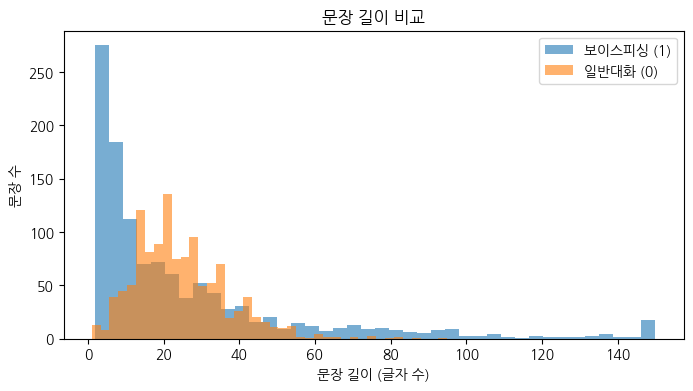

In [10]:
print(balanced.groupby("label")["length"].describe().round(1))

plt.figure(figsize=(8, 4))
plt.hist(balanced[balanced.label == 1]["length"].clip(upper=150), bins=40, alpha=0.6, label="보이스피싱 (1)")
plt.hist(balanced[balanced.label == 0]["length"].clip(upper=150), bins=40, alpha=0.6, label="일반대화 (0)")
plt.xlabel("문장 길이 (글자 수)")
plt.ylabel("문장 수")
plt.legend()
plt.title("문장 길이 비교")
plt.show()

## 2. 길이만으로 구분해보기
- 보이스피싱은 whisper로 텍스트화 한것, 일반대화데이터는 처음부터 텍스트
-> 말투, 길이 차이가 생길 수 있음
- 글자수만 보고 분류하는 간단한 모델 테스트

In [11]:
X = balanced[["length"]]
y = balanced["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

length_model = LogisticRegression().fit(X_train, y_train)
length_acc = accuracy_score(y_test, length_model.predict(X_test))
print(f"길이만으로 맞힌 정확도: {length_acc:.1%}  (찍으면 50%)")

길이만으로 맞힌 정확도: 48.9%  (찍으면 50%)


## 3. 자주 나오는 단어 비교
- 비율: 보이스피싱에서 나온 횟수 / 일반대화에서 나온 횟수

In [12]:
def words(text):
    return [w for w in re.findall(r"[가-힣]+", str(text)) if len(w) >= 2]

count_1 = Counter(w for t in balanced[balanced.label == 1]["text"] for w in words(t))
count_0 = Counter(w for t in balanced[balanced.label == 0]["text"] for w in words(t))

word_df = pd.DataFrame({"보이스피싱": count_1, "일반대화": count_0}).fillna(0).astype(int)
word_df = word_df[word_df.sum(axis=1) >= 10]      # 너무 드문 단어 제외
word_df["비율"] = ((word_df["보이스피싱"] + 1) / (word_df["일반대화"] + 1)).round(1)

print("[보이스피싱에서 많이 나오는 단어]")
display(word_df.sort_values("비율", ascending=False).head(15))
print("[일반대화에서 많이 나오는 단어]")
display(word_df.sort_values("비율").head(15))

[보이스피싱에서 많이 나오는 단어]


,보이스피싱,일반대화,비율
김승재,60,0,61.0
고객님,59,0,60.0
저희가,53,0,54.0
통해,37,0,38.0
사안을,37,0,38.0
본인이,32,0,33.0
고객님께서,27,0,28.0
저희,50,1,25.5
아니요,23,0,24.0
대출,18,0,19.0


[일반대화에서 많이 나오는 단어]


,보이스피싱,일반대화,비율
같아,0,49,0.0
너는,0,22,0.0
약간,0,22,0.0
나는,1,64,0.0
진짜,2,22,0.1
있어,1,23,0.1
정말,1,18,0.1
인제,1,26,0.1
좋아하는,0,15,0.1
굉장히,1,16,0.1


## 4. 통화별 문장 수(보이스피싱)

count     31.0
mean      37.9
std       33.4
min        2.0
25%       15.0
50%       24.0
75%       56.0
max      141.0
dtype: float64


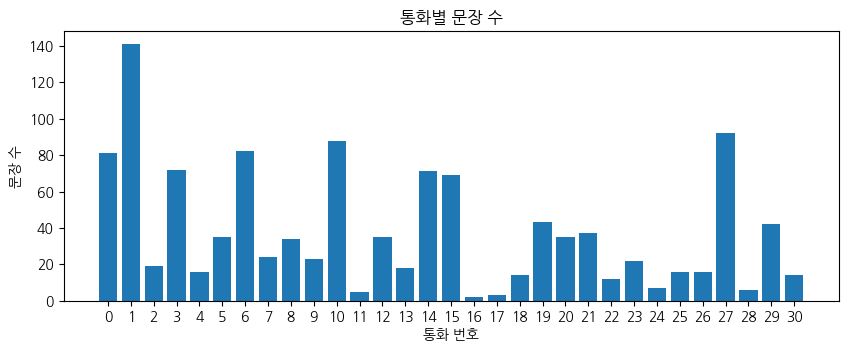

In [13]:
sent_per_call = call_sents.groupby("call_id").size()
print(sent_per_call.describe().round(1))

plt.figure(figsize=(10, 3.5))
plt.bar(sent_per_call.index.astype(str), sent_per_call.values)
plt.xlabel("통화 번호")
plt.ylabel("문장 수")
plt.title("통화별 문장 수")
plt.show()

# 토크나이저/모델 준비

In [14]:
from transformers import AutoTokenizer
MODEL_NAME = "skt/kobert-base-v1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/535 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/371k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

In [15]:
# 텍스트를 토큰화 함수
def tokenize_function(examples):
    tokenized_output = tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)
    # 단일 문장 분류의 경우 token_type_ids를 모두 0으로 설정
    tokenized_output["token_type_ids"] = [[0] * 128 for _ in range(len(examples["text"]))]
    return tokenized_output

# Pandas DataFrame을 Hugging Face Dataset으로 변환
train_dataset = Dataset.from_pandas(train_df)
valid_dataset = Dataset.from_pandas(valid_df)
test_dataset = Dataset.from_pandas(test_df)

print("✅ Hugging Face 데이터셋으로 변환 완료")

# pandas에서 변환 시 자동으로 생성될 수 있는 불필요한 index 컬럼을 제거
if '__index_level_0__' in train_dataset.column_names:
    train_dataset = train_dataset.remove_columns(['__index_level_0__'])
if '__index_level_0__' in valid_dataset.column_names:
    valid_dataset = valid_dataset.remove_columns(['__index_level_0__'])
if '__index_level_0__' in test_dataset.column_names:
    test_dataset = test_dataset.remove_columns(['__index_level_0__'])

✅ Hugging Face 데이터셋으로 변환 완료


# 데이터 토큰화

In [16]:
# 데이터셋에 토크나이저 적용
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_valid = valid_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

# 모델 학습에 필요한 컬럼만 남기기
tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_train.set_format("torch")

tokenized_valid = tokenized_valid.remove_columns(["text"])
tokenized_valid = tokenized_valid.rename_column("label", "labels")
tokenized_valid.set_format("torch")

tokenized_test = tokenized_test.remove_columns(["text"])
tokenized_test = tokenized_test.rename_column("label", "labels")
tokenized_test.set_format("torch")

print("✅ 데이터 토큰화 및 포맷 설정 완료")

Map:   0%|          | 0/2424 [00:00<?, ? examples/s]

Map:   0%|          | 0/303 [00:00<?, ? examples/s]

Map:   0%|          | 0/303 [00:00<?, ? examples/s]

✅ 데이터 토큰화 및 포맷 설정 완료


# DataLoader 생성

In [17]:
batch_size = 32

train_dataloader = DataLoader(tokenized_train, shuffle=True, batch_size=batch_size)
eval_dataloader = DataLoader(tokenized_valid, batch_size=batch_size)
test_dataloader = DataLoader(tokenized_test, batch_size=batch_size)

print("✅ 데이터로더 생성 완료")

✅ 데이터로더 생성 완료


In [18]:
# GPU 사용 가능 여부 확인 및 장치 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# 모델 및 옵티마이저 설정

In [ ]:
# 사전 학습된 KoBERT 모델 불러오기(분류)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model.to(device)

# 옵티마이저(AdamW) 설정
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)

# 학습률 설정
num_epochs = 5
num_training_steps = num_epochs * len(train_dataloader)
lr_scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=0, num_training_steps=num_training_steps
)

print("✅ 모델 및 학습 설정 완료.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: skt/kobert-base-v1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ 모델 및 학습 설정 완료.


# 모델학습

In [ ]:
progress_bar = tqdm(range(num_training_steps))

for epoch in range(num_epochs):
    # 학습
    model.train()
    for batch in train_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        progress_bar.update(1)

    # 평가
    model.eval()
    all_preds = []
    all_labels = []
    for batch in eval_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.no_grad():
            outputs = model(**batch)

        logits = outputs.logits
        predictions = torch.argmax(logits, dim=-1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

    # 검증 성능 계산 시 모든 지표 추가
    eval_accuracy = accuracy_score(all_labels, all_preds)
    eval_precision = precision_score(all_labels, all_preds)
    eval_recall = recall_score(all_labels, all_preds)
    eval_f1 = f1_score(all_labels, all_preds)
    print(f"\n🚀 Epoch {epoch+1} | Validation Accuracy: {eval_accuracy:.4f} | Precision: {eval_precision:.4f} | Recall: {eval_recall:.4f} | F1: {eval_f1:.4f}")

  0%|          | 0/380 [00:00<?, ?it/s]


🚀 Epoch 1 | Validation Accuracy: 0.7360 | Precision: 0.6565 | Recall: 0.9934 | F1: 0.7906

🚀 Epoch 2 | Validation Accuracy: 0.7855 | Precision: 0.7042 | Recall: 0.9868 | F1: 0.8219

🚀 Epoch 3 | Validation Accuracy: 0.8053 | Precision: 0.7225 | Recall: 0.9934 | F1: 0.8366

🚀 Epoch 4 | Validation Accuracy: 0.8185 | Precision: 0.7680 | Recall: 0.9145 | F1: 0.8348

🚀 Epoch 5 | Validation Accuracy: 0.8185 | Precision: 0.7594 | Recall: 0.9342 | F1: 0.8378


# 모델 저장

In [ ]:
import os

SAVE_PATH = "/content/drive/MyDrive/hanieum/추후수정본"   # 팀 모델(hanieum/)과 겹치지 않게 다른 폴더
os.makedirs(SAVE_PATH, exist_ok=True)

model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/hanieum/추후수정본/tokenizer_config.json',
 '/content/drive/MyDrive/hanieum/추후수정본/tokenizer.json')

In [19]:
LOAD_PATH = "/content/drive/MyDrive/hanieum/추후수정본"

model = AutoModelForSequenceClassification.from_pretrained(LOAD_PATH)
tokenizer = AutoTokenizer.from_pretrained(LOAD_PATH)
model.to(device)
print("✅ 저장된 모델을 불러왔습니다.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ 저장된 모델을 불러왔습니다.


# 최종평가

In [21]:
print("\n✅ 학습 완료! 최종 테스트를 진행합니다...")
model.eval()
all_preds = []
all_labels = []
all_probs = []   # ← 추가: 보이스피싱일 확률

for batch in test_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    with torch.no_grad():
        outputs = model(**batch)

    logits = outputs.logits
    predictions = torch.argmax(logits, dim=-1)
    all_preds.extend(predictions.cpu().numpy())
    all_labels.extend(batch["labels"].cpu().numpy())
    all_probs.extend(torch.softmax(logits, dim=-1)[:, 1].cpu().numpy())   # ← 추가

test_accuracy = accuracy_score(all_labels, all_preds)
test_precision = precision_score(all_labels, all_preds)
test_recall = recall_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds)

print("\n====== 최종 테스트 결과 ======")
print(f"Accuracy (정확도): {test_accuracy:.4f}")
print(f"Precision (정밀도): {test_precision:.4f}")
print(f"Recall (재현율): {test_recall:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print("============================")


✅ 학습 완료! 최종 테스트를 진행합니다...

====== 최종 테스트 결과 ======
Accuracy (정확도): 0.8284
Precision (정밀도): 0.8000
Recall (재현율): 0.8742
F1 Score: 0.8354


# 베이스라인 비교
- 키워드 사전: 위험 단어가 하나라도 있으면 보이스피싱
- TF-IDF + 로지스틱 회귀: 문장을 쪼깨 빈도를 학습

In [22]:
def get_scores(labels, probs, threshold=0.5):
    labels = np.array(labels)
    preds = (np.array(probs) >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(labels, preds),
        "Precision": precision_score(labels, preds, zero_division=0),
        "Recall": recall_score(labels, preds, zero_division=0),
        "F1": f1_score(labels, preds, zero_division=0),
        "FPR": ((preds == 1) & (labels == 0)).sum() / (labels == 0).sum(),   # 일반대화를 잘못 경고한 비율
    }

# test_df에 KoBERT 결과 붙이기 (test_dataloader는 섞지 않아서 순서가 같음)
test_result = test_df.copy()
test_result["kobert_prob"] = all_probs
test_result["kobert_pred"] = (test_result["kobert_prob"] >= 0.5).astype(int)
print(get_scores(test_result["label"], test_result["kobert_prob"]))

{'Accuracy': 0.8283828382838284, 'Precision': 0.8, 'Recall': 0.8741721854304636, 'F1': 0.8354430379746836, 'FPR': np.float64(0.21710526315789475)}


In [23]:
# 1) 키워드 사전
RISK_KEYWORDS = ["검찰", "검사", "수사", "경찰", "금융감독원", "금감원", "사건", "연루", "명의", "피해자", "피의자",
                 "대포통장", "녹취", "진술", "계좌", "이체", "송금", "현금", "인출", "대출", "저금리", "대환",
                 "상환", "한도", "신용", "앱", "설치", "링크", "자금", "불법"]
test_result["keyword_prob"] = test_result["text"].map(lambda t: 1.0 if any(k in str(t) for k in RISK_KEYWORDS) else 0.0)

# 2) TF-IDF + 로지스틱 회귀 (KoBERT와 같은 train_df로 학습)
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_result["text"])
tfidf_model = LogisticRegression(max_iter=2000).fit(X_train, train_df["label"])
test_result["tfidf_prob"] = tfidf_model.predict_proba(X_test)[:, 1]

# 비교표
compare = pd.DataFrame({
    "키워드 사전": get_scores(test_result["label"], test_result["keyword_prob"]),
    "TF-IDF + 로지스틱 회귀": get_scores(test_result["label"], test_result["tfidf_prob"]),
    "KoBERT": get_scores(test_result["label"], test_result["kobert_prob"]),
}).T
compare.round(4)

,Accuracy,Precision,Recall,F1,FPR
키워드 사전,0.6436,0.9778,0.2914,0.4490,0.0066
TF-IDF + 로지스틱 회귀,0.9373,0.9286,0.9470,0.9377,0.0724
KoBERT,0.8284,0.8000,0.8742,0.8354,0.2171


# 결과 저장

In [ ]:
test_result.to_csv("/content/drive/MyDrive/hanieum/추후수정본/test_result.csv", index=False, encoding="utf-8-sig")

In [24]:
test_result = pd.read_csv("/content/drive/MyDrive/hanieum/추후수정본/test_result.csv")
print(f"✅ 평가 결과를 불러왔습니다: {len(test_result)}문장")

✅ 평가 결과를 불러왔습니다: 303문장


# 오류분석
- 혼동행렬: 어느 쪽으로 더 많이 틀렸는가
- 놓친 보이스피싱/잘못 경고한 일반대화
- 키워드는 놓쳤지만 KoBERT가 잡은 문장
- 문장 길이별 정확도

In [25]:
pd.set_option("display.max_colwidth", 150)

# 1. 혼동행렬
cm = confusion_matrix(test_result["label"], test_result["kobert_pred"], labels=[0, 1])
display(pd.DataFrame(cm, index=["실제 일반대화", "실제 보이스피싱"], columns=["일반대화로 예측", "보이스피싱으로 예측"]))

# 2. 틀린 문장
missed = test_result[(test_result.label == 1) & (test_result.kobert_pred == 0)].sort_values("kobert_prob")
false_alarm = test_result[(test_result.label == 0) & (test_result.kobert_pred == 1)].sort_values("kobert_prob", ascending=False)
print(f"놓친 보이스피싱: {len(missed)}문장")
display(missed[["kobert_prob", "text"]].head(10))
print(f"잘못 경고한 일반대화: {len(false_alarm)}문장")
display(false_alarm[["kobert_prob", "text"]].head(10))

# 3. 키워드 없이도 KoBERT가 잡은 보이스피싱
bert_only = test_result[(test_result.label == 1) & (test_result.kobert_pred == 1) & (test_result.keyword_prob == 0)]
print(f"키워드는 놓쳤지만 KoBERT가 잡은 보이스피싱: {len(bert_only)}문장")
display(bert_only[["kobert_prob", "text"]].head(10))

# 4. 문장 길이별 정확도
test_result["length"] = test_result["text"].astype(str).str.len()
test_result["correct"] = test_result["label"] == test_result["kobert_pred"]
test_result["length_group"] = pd.cut(test_result["length"], bins=[0, 10, 20, 40, 1000],
                                     labels=["10자 이하", "11~20자", "21~40자", "41자 이상"])
display(test_result.groupby("length_group", observed=True)["correct"].agg(문장수="size", 정확도="mean").round(3))

,일반대화로 예측,보이스피싱으로 예측
실제 일반대화,119,33
실제 보이스피싱,19,132


놓친 보이스피싱: 19문장


,kobert_prob,text
22,0.059663,어 지금 현재 같이 있는 게 아니기 때문에.
214,0.062507,아무래도 이런 공문 같은 경우.
40,0.150512,마지막으로 본인이 합법적인 자산에 대해서 간략하게 진술을 받겠는데 금액적인 부분까지 여쭤보는 이유는 마찬가지로 조사를
245,0.253298,공무소 위조 혐의까지는 적응이 좀 될 수 있어요.
16,0.256843,본 검사 이름도 얘기했고 본인 공무장도 보여드렸고.
91,0.277356,근데 불법 자금이 관련이 돼 있어요.
290,0.289389,방에 지금 그냥 이렇게 해도 들려요.
224,0.323341,자 그러면은 거기 보시면은.
17,0.325883,물론 이 서류 중에 녹취 파일 그만큼 중요하기 때문에.
242,0.398078,이게 만약에 증거처로서 체결되기 위해서는.


잘못 경고한 일반대화: 33문장


,kobert_prob,text
147,0.984346,한신 치킨은 바삭한 튀김옷과 촉촉한 속살이 특징인 치킨 요리로 유명해.
254,0.935738,그거 봤어 미스터 선샤인?
209,0.920363,그러면은 금액에 비례해 가지고 1.5프로씩 현금으로 줘.
53,0.917438,뚫고 더 올라가지 않을까 분위기상?
5,0.886538,아이들도 불편하다고 생각하거든.
114,0.876946,돌아다니고 있어요.
249,0.858984,너는 미술관이나 이런 전시는 별로 좋아하지 않아?
58,0.854139,저요?
255,0.844229,이제 둘이 바다로 달려갑니다.
131,0.827369,대학교 오기를 되게 잘했다고 생각이 항상 들어요.


키워드는 놓쳤지만 KoBERT가 잡은 보이스피싱: 93문장


,kobert_prob,text
1,0.744003,이런 사람들 지금 저희들한테 29명이 근거가 됐는데.
4,0.730337,어 주소창에 지금 시간이 55분이기 때문에 주소창 보시면은.
9,0.782753,미리 좀 제가 상황을 말씀을 드린 거였는데.
12,0.738697,자 그 우리은행 들어가서 5만원 거 얼마나 찾을 수 있는지 물어보고 찾을 수 있는 데까지 찾고 이거 달러로 좀 바꿔주세요 라고 하세요.
19,0.984576,1200만원 맞으시고 일단은 지금 본인 해지 업무 보셨고 가까운 우리은행 방문하시는데 이제 이동하시는 이동 소요 시간 같은 게 얼마나 걸리시겠어요?
25,0.978638,그렇게 되시면 평균이 오르긴 합니다만 500만 원 이상 목돈을 넣어두시고 한 3개월 이상 정도 기다리셔야 하시거든요.
29,0.801616,인터넷 판매 사이트인데 사이트 자체가 이 판매 사이트를 악용을 했어요.
32,0.935432,전화 끊지 마시고 갖고 5만원 빼셨으니까.
34,0.931360,그래서 오늘 내용 증명서를 제가 본인 약식에 대한 조사를 진행을 좀 도와드리고.
43,0.567225,새마을 근데 좀 많아요.


,문장수,정확도
length_group,,
10자 이하,29,0.793
11~20자,84,0.798
21~40자,130,0.815
41자 이상,60,0.917


In [28]:
# 보이스피싱 -> 일반대화로 판단(19)
missed['text']

,text
22,어 지금 현재 같이 있는 게 아니기 때문에.
214,아무래도 이런 공문 같은 경우.
40,마지막으로 본인이 합법적인 자산에 대해서 간략하게 진술을 받겠는데 금액적인 부분까지 여쭤보는 이유는 마찬가지로 조사를
245,공무소 위조 혐의까지는 적응이 좀 될 수 있어요.
16,본 검사 이름도 얘기했고 본인 공무장도 보여드렸고.
91,근데 불법 자금이 관련이 돼 있어요.
290,방에 지금 그냥 이렇게 해도 들려요.
224,자 그러면은 거기 보시면은.
17,물론 이 서류 중에 녹취 파일 그만큼 중요하기 때문에.
242,이게 만약에 증거처로서 체결되기 위해서는.


In [29]:
# 일반대화 -> 보이스피싱으로 판단(33)
false_alarm['text']

,text
147,한신 치킨은 바삭한 튀김옷과 촉촉한 속살이 특징인 치킨 요리로 유명해.
254,그거 봤어 미스터 선샤인?
209,그러면은 금액에 비례해 가지고 1.5프로씩 현금으로 줘.
53,뚫고 더 올라가지 않을까 분위기상?
5,아이들도 불편하다고 생각하거든.
114,돌아다니고 있어요.
249,너는 미술관이나 이런 전시는 별로 좋아하지 않아?
58,저요?
255,이제 둘이 바다로 달려갑니다.
131,대학교 오기를 되게 잘했다고 생각이 항상 들어요.


# 놓친 문장 분석

## 1. 여러 특징 비교

In [31]:
phishing = test_result[test_result["label"] == 1].copy()
phishing["결과"] = np.where(phishing["kobert_pred"] == 1, "잡은 문장", "놓친 문장")

# 일반대화 학습 데이터에 나온 단어 목록 (문장이 얼마나 '일상적인지' 재기 위해)
def words(t):
    return [w for w in re.findall(r"[가-힣]+", str(t)) if len(w) >= 2]
normal_vocab = set(w for t in train_df[train_df["label"] == 0]["text"] for w in words(t))

def normal_word_ratio(t):
    ws = words(t)
    return np.mean([w in normal_vocab for w in ws]) if ws else np.nan

t = phishing["text"].astype(str)
phishing["글자 수"] = t.str.len()
phishing["위험 키워드 포함"] = phishing["keyword_prob"] == 1
phishing["숫자 포함"] = t.str.contains(r"\d")
phishing["물음표 포함"] = t.str.contains(r"\?")
phishing["존댓말로 끝남"] = t.str.strip().str.contains(r"(?:요|니다|니까|세요)[.?!]?$")
phishing["일상 단어 비율"] = t.map(normal_word_ratio)

feature_cols = ["글자 수", "위험 키워드 포함", "숫자 포함", "물음표 포함", "존댓말로 끝남", "일상 단어 비율"]
compare_fn = phishing.groupby("결과")[feature_cols].mean().T
compare_fn["차이 (놓친 − 잡은)"] = compare_fn["놓친 문장"] - compare_fn["잡은 문장"]
print(f"잡은 문장 {(phishing['결과'] == '잡은 문장').sum()}개 / 놓친 문장 {(phishing['결과'] == '놓친 문장').sum()}개")
display(compare_fn.round(3))

잡은 문장 132개 / 놓친 문장 19개


결과,놓친 문장,잡은 문장,차이 (놓친 − 잡은)
글자 수,29.368,36.030,-6.662
위험 키워드 포함,0.263,0.295,-0.032
숫자 포함,0.105,0.174,-0.069
물음표 포함,0.000,0.258,-0.258
존댓말로 끝남,0.368,0.727,-0.359
일상 단어 비율,0.471,0.310,0.161


## 2. 놓친 문장에 유독 많은 단어 찾기

In [ ]:
count_missed = Counter(w for t in phishing[phishing["결과"] == "놓친 문장"]["text"] for w in words(t))
count_caught = Counter(w for t in phishing[phishing["결과"] == "잡은 문장"]["text"] for w in words(t))
n_missed = (phishing["결과"] == "놓친 문장").sum()
n_caught = (phishing["결과"] == "잡은 문장").sum()

word_fn = pd.DataFrame({"놓친 문장": count_missed, "잡은 문장": count_caught}).fillna(0).astype(int)
word_fn = word_fn[word_fn.sum(axis=1) >= 3]   # 너무 드문 단어 제외
word_fn["놓친 쪽 비중"] = (((word_fn["놓친 문장"] + 1) / n_missed) / ((word_fn["잡은 문장"] + 1) / n_caught)).round(2)
word_fn["일반대화에도 나옴"] = word_fn.index.map(lambda w: w in normal_vocab)

print("[놓친 문장에서 유독 많이 나오는 단어]")
display(word_fn.sort_values(["놓친 쪽 비중", "놓친 문장"], ascending=False).head(15))

[놓친 문장에서 유독 많이 나오는 단어]


,놓친 문장,잡은 문장,놓친 쪽 비중,일반대화에도 나옴
근데,3,1,13.89,True
그냥,2,1,10.42,True
이렇게,2,1,10.42,True
만약에,2,2,6.95,True
조사를,2,2,6.95,False
있어요,2,3,5.21,True
거고,1,2,4.63,True
검사,1,2,4.63,True
같이,1,2,4.63,True
받고,1,2,4.63,True


# 잘못 경고한 문장 분석

## 1. 여러 특징 비교

In [ ]:
normal = test_result[test_result["label"] == 0].copy()
normal["결과"] = np.where(normal["kobert_pred"] == 1, "잘못 경고", "맞게 통과")

# 보이스피싱 학습 문장에만 나오는 단어 목록 (일반대화에는 안 나옴)
phishing_vocab = set(w for t in train_df[train_df["label"] == 1]["text"] for w in words(t))
phishing_only_vocab = phishing_vocab - normal_vocab

def phishing_word_ratio(t):
    ws = words(t)
    return np.mean([w in phishing_only_vocab for w in ws]) if ws else np.nan

t = normal["text"].astype(str)
normal["글자 수"] = t.str.len()
normal["위험 키워드 포함"] = normal["keyword_prob"] == 1
normal["숫자 포함"] = t.str.contains(r"\d")
normal["물음표 포함"] = t.str.contains(r"\?")
normal["존댓말로 끝남"] = t.str.strip().str.contains(r"(?:요|니다|니까|세요)[.?!]?$")
normal["보이스피싱 단어 비율"] = t.map(phishing_word_ratio)

feature_cols_fp = ["글자 수", "위험 키워드 포함", "숫자 포함", "물음표 포함", "존댓말로 끝남", "보이스피싱 단어 비율"]
compare_fp = normal.groupby("결과")[feature_cols_fp].mean().T
compare_fp["차이 (잘못 경고 − 맞게 통과)"] = compare_fp["잘못 경고"] - compare_fp["맞게 통과"]
print(f"맞게 통과 {(normal['결과'] == '맞게 통과').sum()}개 / 잘못 경고 {(normal['결과'] == '잘못 경고').sum()}개")
display(compare_fp.round(3))

맞게 통과 119개 / 잘못 경고 33개


결과,맞게 통과,잘못 경고,차이 (잘못 경고 − 맞게 통과)
글자 수,24.328,22.182,-2.146
위험 키워드 포함,0.000,0.030,0.030
숫자 포함,0.076,0.061,-0.015
물음표 포함,0.059,0.182,0.123
존댓말로 끝남,0.050,0.424,0.374
보이스피싱 단어 비율,0.036,0.040,0.004


## 2. 잘못 경고한 문장에 유독 많은 단어 찾기

In [ ]:
count_fp = Counter(w for t in normal[normal["결과"] == "잘못 경고"]["text"] for w in words(t))
count_tn = Counter(w for t in normal[normal["결과"] == "맞게 통과"]["text"] for w in words(t))
n_fp = (normal["결과"] == "잘못 경고").sum()
n_tn = (normal["결과"] == "맞게 통과").sum()

word_fp = pd.DataFrame({"잘못 경고": count_fp, "맞게 통과": count_tn}).fillna(0).astype(int)
word_fp = word_fp[word_fp.sum(axis=1) >= 2]   # 잘못 경고 문장 수가 적어서 기준을 2로 낮춤
word_fp["잘못 경고 쪽 비중"] = (((word_fp["잘못 경고"] + 1) / n_fp) / ((word_fp["맞게 통과"] + 1) / n_tn)).round(2)
word_fp["보이스피싱 학습 데이터에도 나옴"] = word_fp.index.map(lambda w: w in phishing_vocab)

print("[잘못 경고한 문장에서 유독 많이 나오는 단어]")
display(word_fp.sort_values(["잘못 경고 쪽 비중", "잘못 경고"], ascending=False).head(15))

[잘못 경고한 문장에서 유독 많이 나오는 단어]


,잘못 경고,맞게 통과,잘못 경고 쪽 비중,보이스피싱 학습 데이터에도 나옴
않을까,2,0,10.82,False
극혐,2,0,10.82,False
있어요,2,0,10.82,True
때도,2,0,10.82,True
둘이,2,0,10.82,False
진짜,3,1,7.21,False
같은,2,2,3.61,True
없다고,1,1,3.61,True
같아요,1,1,3.61,True
경우에는,1,1,3.61,True


# 실제 환경 해석
- 테스트 데이터는 보이스피싱:일반대화 = 1:1
- 실제 통화에서는 보이스피싱이 훨씬 적음

In [ ]:
# 1. 실제 비율별 정밀도
rows = []
for model_name in compare.index:
    recall, fpr = compare.loc[model_name, "Recall"], compare.loc[model_name, "FPR"]
    for p in [0.5, 0.1, 0.01]:
        precision = (recall * p) / (recall * p + fpr * (1 - p)) if (recall * p + fpr * (1 - p)) > 0 else float("nan")
        rows.append({"모델": model_name, "보이스피싱 비율": f"{p:.0%}", "정밀도": f"{precision:.1%}",
                     "경고 몇 건 중 1건이 진짜": round(1 / precision, 1) if precision > 0 else None})
display(pd.DataFrame(rows))

# 2. 판정 기준값을 바꾸면? (KoBERT)
th_rows = []
for th in [0.5, 0.6, 0.7, 0.8, 0.9]:
    s = get_scores(test_result["label"], test_result["kobert_prob"], threshold=th)
    p = 0.01
    denom = s["Recall"] * p + s["FPR"] * (1 - p)
    th_rows.append({"기준값": th, "Recall": round(s["Recall"], 3), "FPR": round(s["FPR"], 3),
                    "정밀도 (1% 가정)": f"{(s['Recall'] * p / denom):.1%}" if denom > 0 else "-"})
display(pd.DataFrame(th_rows))

,모델,보이스피싱 비율,정밀도,경고 몇 건 중 1건이 진짜
0,키워드 사전,50%,97.8%,1.0
1,키워드 사전,10%,83.1%,1.2
2,키워드 사전,1%,30.9%,3.2
3,TF-IDF + 로지스틱 회귀,50%,92.9%,1.1
4,TF-IDF + 로지스틱 회귀,10%,59.3%,1.7
5,TF-IDF + 로지스틱 회귀,1%,11.7%,8.6
6,KoBERT,50%,80.1%,1.2
7,KoBERT,10%,30.9%,3.2
8,KoBERT,1%,3.9%,25.6


,기준값,Recall,FPR,정밀도 (1% 가정)
0,0.5,0.874,0.217,3.9%
1,0.6,0.815,0.184,4.3%
2,0.7,0.748,0.138,5.2%
3,0.8,0.682,0.079,8.0%
4,0.9,0.444,0.026,14.6%


# TF-IDF + 로지스틱 회귀 / KoBERT 추가 비교

In [ ]:
test_result["tfidf_pred"] = (test_result["tfidf_prob"] >= 0.5).astype(int)

only_tfidf = test_result[(test_result.tfidf_pred == test_result.label) & (test_result.kobert_pred != test_result.label)]
only_bert = test_result[(test_result.kobert_pred == test_result.label) & (test_result.tfidf_pred != test_result.label)]

print(f"TF-IDF만 맞힌 문장: {len(only_tfidf)}개 / KoBERT만 맞힌 문장: {len(only_bert)}개 (전체 {len(test_result)}개)")
print("\n[TF-IDF만 맞힌 문장]")
display(only_tfidf[["label", "tfidf_prob", "kobert_prob", "text"]].head(10))
print("\n[KoBERT만 맞힌 문장]")
display(only_bert[["label", "tfidf_prob", "kobert_prob", "text"]].head(10))

TF-IDF만 맞힌 문장: 41개 / KoBERT만 맞힌 문장: 8개 (전체 303개)

[TF-IDF만 맞힌 문장]


,label,tfidf_prob,kobert_prob,text
410,0,0.129930,0.886538,아이들도 불편하다고 생각하거든.
541,1,0.662490,0.497114,그러면 저기 본인께서 기분도 나쁘실 거고 만약에 가담하신 게 아니게 된다면 기분도 나쁘고 그럴 건데.
1520,0,0.128198,0.643781,여기 진짜 내 인생 막국수라고 해도 될 만큼 너무 맛있었어.
2051,0,0.257975,0.735673,엠비티아이가 사람의 성격을 다 나타낼 순 없다고 생각해요.
998,0,0.308785,0.794639,네. 먹어 봤죠.
1831,1,0.787659,0.256843,본 검사 이름도 얘기했고 본인 공무장도 보여드렸고.
816,1,0.658761,0.325883,물론 이 서류 중에 녹취 파일 그만큼 중요하기 때문에.
889,1,0.814031,0.150512,마지막으로 본인이 합법적인 자산에 대해서 간략하게 진술을 받겠는데 금액적인 부분까지 여쭤보는 이유는 마찬가지로 조사를
2211,0,0.339436,0.563499,진짜 그땐 센세이셔널했던 거 같아요.
1107,0,0.089905,0.611854,나 같은 경우에는 갑자기 2년 만에 딱 나오다 보니까 그런 게 되게 신기했거든.



[KoBERT만 맞힌 문장]


,label,tfidf_prob,kobert_prob,text
1636,0,0.542339,0.006645,공복인 상태가 유지되니까
2215,1,0.425594,0.983111,이 방법은 그래서 제가 기간이 좀 걸리니까 추천 드리지는 않고 단시간에 시행점수를 상향시킬 수 있는 방법이 있는데 채무상환능력 평가라는 방법이에요.
2092,1,0.489494,0.567225,새마을 근데 좀 많아요.
1633,0,0.531662,0.006494,이후 2750만 원으로 하향 조정하면서
1289,1,0.309657,0.931268,그다음에 오케이 캐피탈인가?
13,1,0.348481,0.678315,왜냐하면.
974,1,0.450191,0.798012,아 명품 같은 거를 저가에 판매를 한다고 글을 작성하고 올립니다.
2284,0,0.506893,0.006627,결국 최종적으로 피해 보는 건 전통 시장들이라


# 인사이트 정리
1. KoBERT가 필요한가?
- 키워드 사전 F1: 0.4000
- KoBERT F1: 0.8553
- 키워드 놓쳤지만 보이스피싱 잡은 문장: 96

2. 어떤 문장을 놓치나?
- 평균글자수: 놓친 문장 27자 vs 잡은 문장 36자  
-> 놓친 문장의 글자수가 약 25% 짧음
- 존댓말의 비율: 놓친 문장 42% vs 잡은 문장 72%  
-> 존댓말로 끝나면 보이스피싱으로 판단하는 경향
- 일상단어 비율: 놓친 문장 48% vs 잡은 문장 30%  
-> 놓친 문장이 일상 단어를 약 1.6배 더 많이 쓰고있음

결과의 해석: 모델이 놓치고 있는 문장은 짧고, 반말이 섞이고, 일상 대화처럼 들리는 문장

3. 무엇을 잘못 경고하나?
- 보이스피싱으로 잘못 경고한 문장 중 존댓말로 끝나는 비율: 42%
- 일반대화로 맞게 판단한 문장 중 존댓말로 끝나는 비율: 5%  
-> 존댓말을 쓰는 대화를 보이스피싱으로 판단하는 경향이 있음  
-> 존댓말을 쓰는 일반대화 데이터를 학습에 추가할 필요가 있어보임

4. 짧은 문장에 약한가?
- 40자 이하 문장 별 정확도: 0.79~0.81
- 41자 이상 문장 별 정확도: 0.91  
-> 40자 이하의 문장은 앞뒤 문장을 함께 보는 방식이 필요함

5. 실제로 쓸 수 있나?(실제 환경처럼 전체 데이터 중 보이스피싱 비율이 1%라고 가정)
- 키워드 사전 정밀도: 30.9%
- TF-IDF + 로지스틱 회귀 정밀도: 11.7%
- KoBERT 정밀도: 3.9%
